# Serial against parallel: one small search, timed

How much faster does a gecko search run through `ariel.simulation.process_pool`
than in one process, and does it find exactly the same thing? This notebook
runs one small experiment twice over and times it:

* Searches: CMA-ES over the parameters of `PhaseCPG` and `TegotaeCPG`, seeds 0
  and 1, so four independent searches.
* Each search: 3 generations of 8 candidates, 24 trials of 10 s on the
  gecko (`gecko_trials.walk`, the trial of `cpg_locomotion`), 96 trials in
  all.
* Serial: every trial in this process, one after another.
* Pool: the same trials sent to `process_pool` with 2, 4, 8 and 16 worker
  processes. The time includes starting the pool.

The searches run in lockstep rounds. In one round each search asks CMA-ES for
a whole generation (8 candidates), the 32 trials of the round are scored
together (a `for` loop, or one `pool.map`), and each search is told its scores
in the order it asked. CMA-ES then sees exactly what it would have seen
serially, so both ways must give the same distances to the last digit.

In [1]:
# Standard library
import os
import time

# Third-party libraries
import matplotlib.pyplot as plt
import nevergrad as ng
import numpy as np
from rich.console import Console

# Local libraries
from ariel.simulation import process_pool

%matplotlib inline
plt.rcParams["figure.dpi"] = 50  # keeps the notebook small
console = Console()

CPGS = ["PhaseCPG", "TegotaeCPG"]
SEEDS = [0, 1]
POPSIZE = 8  # candidates per CMA-ES generation
GENERATIONS = 3
WORKERS = [2, 4, 8, 16]
MIN_SPEEDUP = 1.5  # the fastest pool must beat serial by at least this
TRIALS = len(CPGS) * len(SEEDS) * POPSIZE * GENERATIONS

console.print(
    f"{os.cpu_count()} logical CPUs; {len(CPGS) * len(SEEDS)} searches,"
    f" {TRIALS} trials of 10 s"
)

16 logical CPUs; 4 searches, 96 trials of 10 s

In [2]:
# The trials live in gecko_trials.py, beside this notebook: a pool worker can
# import a function from a file, never from a notebook cell
from gecko_trials import CLASSES, Walk, walk, walker

## The search

`start` sets up one search the way `cpg_locomotion` does: CMA-ES over the unit
cube, each parameter scaled to the range the CPG samples it from, starting at
the CPG's own seeded parameters. `search(evaluate)` runs all four in lockstep
rounds; `evaluate` takes the list of `Walk` jobs of a round and returns their
distances in the same order. That function is the only thing that differs
between the serial and the parallel run.

A pool only gives the serial answer if a trial gives the same distance every
time it runs, so the section ends by running one trial twice.

In [3]:
def start(name, seed):
    """Set up one search: its optimizer and its parameter bounds.

    Returns
    -------
    tuple[ng.optimizers.base.Optimizer, np.ndarray, np.ndarray]
        CMA-ES over the unit cube, and the lower and upper bounds.
    """
    cpg = CLASSES[name](walker().adjacency, seed=seed)
    lower, upper = (b.numpy() for b in cpg.parameter_bounds())
    parametrization = ng.p.Array(
        shape=(cpg.num_of_parameters,), lower=0, upper=1
    )
    parametrization.value = (cpg.get_flat_params().numpy() - lower) / (
        upper - lower
    )
    parametrization.random_state = np.random.RandomState(seed)
    optimizer = ng.optimizers.ParametrizedCMA(popsize=POPSIZE)(
        parametrization=parametrization, budget=POPSIZE * GENERATIONS
    )
    return optimizer, lower, upper


def search(evaluate):
    """Run every search in lockstep rounds, one generation per round.

    Returns
    -------
    dict[tuple[str, int], np.ndarray]
        The distance of every trial of each search, in asking order.
    """
    runs = {(name, seed): start(name, seed) for name in CPGS for seed in SEEDS}
    scores = {key: [] for key in runs}
    for _ in range(GENERATIONS):
        asked = {
            key: [optimizer.ask() for _ in range(POPSIZE)]
            for key, (optimizer, _, _) in runs.items()
        }
        jobs = [
            Walk(
                cpg=name,
                seed=seed,
                params=(lower + c.value * (upper - lower)).tolist(),
            )
            for (name, seed), (_, lower, upper) in runs.items()
            for c in asked[name, seed]
        ]
        distances = iter(evaluate(jobs))
        for key, (optimizer, _, _) in runs.items():
            for candidate in asked[key]:
                distance = next(distances)
                optimizer.tell(candidate, -distance)  # CMA-ES minimises
                scores[key].append(distance)
    return {key: np.array(values) for key, values in scores.items()}


optimizer, lower, upper = start("PhaseCPG", 0)
job = Walk(
    cpg="PhaseCPG",
    seed=0,
    params=(lower + optimizer.ask().value * (upper - lower)).tolist(),
)
first, second = walk(job), walk(job)
console.print(f"one trial twice: {first:.9f} m and {second:.9f} m")
assert first == second

one trial twice: 0.201377552 m and 0.201377552 m

## Serial

Every trial in this process, one after another.

In [4]:
started = time.perf_counter()
serial = search(lambda jobs: [walk(job) for job in jobs])
serial_seconds = time.perf_counter() - started

best = max(scores.max() for scores in serial.values())
console.print(
    f"serial: {TRIALS} trials in {serial_seconds:.1f} s"
    f" ({serial_seconds / TRIALS:.3f} s per trial), best {best:.3f} m"
)
assert sum(len(scores) for scores in serial.values()) == TRIALS
assert all(np.isfinite(scores).all() for scores in serial.values())

serial: 96 trials in 35.9 s (0.373 s per trial), best 1.103 m

## Through the pool

The same searches with `pool.map(walk, jobs)` as `evaluate`, once per worker
count. Each run opens its own pool, so its time includes the few seconds the
workers need to import torch, MuJoCo and ARIEL. Every distance must equal the
serial one exactly.

In [5]:
def pooled_search(workers):
    """Run the searches through a pool of ``workers`` processes.

    Returns
    -------
    tuple[dict[tuple[str, int], np.ndarray], float]
        The distances, as ``search`` returns them, and the wall time in
        seconds, pool start-up included.
    """
    started = time.perf_counter()
    with process_pool(workers) as pool:
        scores = search(lambda jobs: list(pool.map(walk, jobs)))
    return scores, time.perf_counter() - started


pooled, seconds = {}, {}
for workers in WORKERS:
    pooled[workers], seconds[workers] = pooled_search(workers)
    console.print(
        f"{workers:2d} workers: {seconds[workers]:5.1f} s,"
        f" {serial_seconds / seconds[workers]:.1f}x faster than serial"
    )

for workers, scores in pooled.items():
    for key, values in serial.items():
        assert np.array_equal(scores[key], values), (workers, key)

2 workers:  21.2 s, 1.7x faster than serial

4 workers:  12.3 s, 2.9x faster than serial

8 workers:  10.2 s, 3.5x faster than serial

16 workers:  11.5 s, 3.1x faster than serial

## Time and speed-up

Left, the wall time of each run; right, the speed-up (serial time over pool
time) against the ideal, where n workers would be n times faster. The gap to
the ideal comes from the pool's start-up, from rounds that do not divide
evenly over the workers (32 trials per round), and, past the number of
physical cores, from two workers sharing one core.

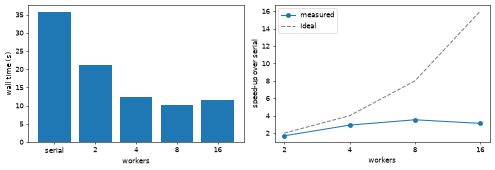

fastest: 8 workers, 3.5x

In [6]:
speedup = {workers: serial_seconds / seconds[workers] for workers in WORKERS}
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5))
labels = ["serial", *(f"{workers}" for workers in WORKERS)]
left.bar(labels, [serial_seconds, *seconds.values()], color="tab:blue")
left.set_xlabel("workers")
left.set_ylabel("wall time (s)")
right.plot(WORKERS, list(speedup.values()), "o-", label="measured")
right.plot(WORKERS, WORKERS, "--", color="grey", label="ideal")
right.set_xscale("log", base=2)
right.set_xticks(WORKERS, [str(workers) for workers in WORKERS])
right.set_xlabel("workers")
right.set_ylabel("speed-up over serial")
right.legend()
fig.tight_layout()
plt.show()

fastest = max(speedup, key=speedup.get)
console.print(f"fastest: {fastest} workers, {speedup[fastest]:.1f}x")
assert len(fig.axes) == len(["time", "speed-up"])
assert speedup[fastest] > MIN_SPEEDUP, speedup

## What this shows

The pool changes the time, not the result: every one of the 96 distances is
the same with any number of workers. The speed-up grows with the workers up
to about the number of physical cores and flattens after, and for a run this
small the seconds the pool needs to start are a visible share of its time. A
longer experiment, such as `cpg_locomotion` with 3,150 trials, opens its pool
once and spends that start-up only once.